# FDTD basics: pulses, absorbing boundaries, a Bragg mirror and a cylinder

The finite-difference time-domain method (FDTD, Yee 1966) solves Maxwell's
curl equations directly: E and H are sampled on two grids shifted by half a
cell, in time by half a step, and leapfrog each other,

$$\frac{\partial \mathbf H}{\partial t} = -\nabla\times\mathbf E,\qquad
\varepsilon\,\frac{\partial \mathbf E}{\partial t} + \sigma\mathbf E = \nabla\times\mathbf H - \mathbf J$$

(normalized units: $c = \varepsilon_0 = \mu_0 = 1$, lengths and wavelengths
in the same unit, times in that unit over $c$). Nothing is assumed about the
structure: no paraxial or one-way approximation as in the WPM (notebook
[05](05_WPM.ipynb)), no periodicity as in RCWA (notebook
[37](37_litho_mask_models.ipynb)). A single run with a short pulse gives the
response over a whole band.

This notebook introduces `pyoptics.fdtd` (1D and 2D, NumPy) and checks it
against exact results already in pyoptics:

1. a pulse from a point source, snapshots and an animation,
2. absorbing boundaries: the convolutional PML against a PEC box,
3. 1D: the reflectance of a Bragg mirror over a whole band from one pulse,
   against `thin_films`,
4. 2D: plane wave scattering by a glass cylinder (total-field /
   scattered-field source) against the exact series `analytical.cylinder_field`,
   and its steady state animated from a single DFT,
5. the two polarizations Ez and Hz,
6. storing results: snapshots, compression and HDF5.

**Ez and Hz.** A 2D simulation (invariant along z) splits into two
independent polarizations, named here after the field component along z:
`mode="Ez"` (E out of the plane; Ez, Hx, Hy) and `mode="Hz"` (Ex, Ey, Hz).
The FDTD books call Ez "TM" (H transverse to z); in waveguide, grating and
scattering texts (and in `litho.rcwa` and `analytical.cylinder_field`) the
same Ez case is "TE", because E is perpendicular to the plane of incidence.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

from pyoptics import fdtd
from pyoptics.fdtd import plot as fplot
from pyoptics.thin_films import r_t_coeffs
from pyoptics.analytical import cylinder_field

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "animation.html": "jshtml", "animation.embed_limit": 30})

## 1. A pulse from a point source

A 2D domain of 10 × 8 wavelengths (λ = 1) with a glass block (n = 1.5) and
a silicon-like rod (n = 3.5), 20 cells per wavelength in vacuum (13.3 in
glass, 6 in the rod: coarse, but fine for a picture). A soft current source
(a line current along z, `PointSource`) emits a Gaussian pulse with 30 %
bandwidth. A 12 cell PML (hatched) absorbs everything that leaves the domain.
`Snapshots` records every 10th step of Ez as float16.

Grid(shape=(200, 160), spacing=(np.float64(0.05), np.float64(0.05)), origin=(np.float64(-5.0), np.float64(-4.0)))  dt = 0.0350  steps per period: 29


458 steps in 0.27 s (54.6 Mcell updates/s)


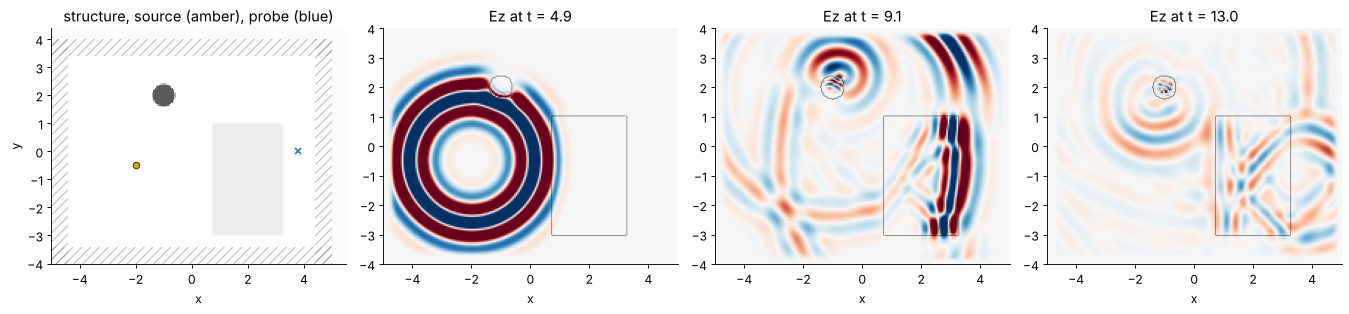

In [2]:
WL = 1.0
grid = fdtd.Grid((10.0, 8.0), WL/20)
glass, rod = fdtd.Medium.from_index(1.5), fdtd.Medium.from_index(3.5)
structure = [(fdtd.Rect((2.0, -1.0), (2.5, 4.0)), glass),
             (fdtd.Circle((-1.0, 2.0), 0.4), rod)]
pulse = fdtd.GaussianPulse(WL, bandwidth=0.3)
snaps = fdtd.Snapshots(every=10)
probe = fdtd.Probe((3.8, 0.0))
sim = fdtd.Simulation(grid, structure, sources=[fdtd.PointSource((-2.0, -0.5), pulse)],
                      monitors=[snaps, probe], boundaries=fdtd.PML(12))
print(grid, " dt = %.4f" % sim.dt, " steps per period: %.0f" % (WL/sim.dt))
sim.run(time=16, progress=True)

stack = snaps.stack()
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
fplot.plot_structure(sim, ax=axs[0])
axs[0].set_title("structure, source (amber), probe (blue)")
for ax, t in zip(axs[1:], (5.0, 9.0, 13.0)):
    k = np.argmin(np.abs(stack.times - t))
    ax.imshow(stack.frames[k].astype(float).T, origin="lower", extent=grid.extent,
              cmap="RdBu_r", vmin=-0.12, vmax=0.12)
    fplot._structure_outline(ax, sim)
    ax.set_title("Ez at t = %.1f" % stack.times[k])
    ax.set_xlabel("x")
plt.tight_layout()

The pulse leaves the source as a ring a few wavelengths thick. In the
glass its wavelength shrinks by n and it falls behind the part that
travels in air; the front face reflects part of it back. The small rod of
high index scatters a weaker ring of its own. Most of the light that enters
the block cannot leave through its side faces at steep angles (total
internal reflection) and bounces around inside. The animation below shows
every second recorded frame (`fplot.animate`, stored as a GIF with
`fplot.gif`).

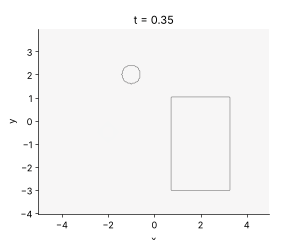

In [3]:
fig, ax = plt.subplots(figsize=(5.0, 4.0))
anim = fplot.animate(fdtd.SnapshotStack(stack.times[::2], stack.coords, stack.frames[::2], "Ez"),
                     sim=sim, ax=ax, vmax=0.12)
plt.close(fig)
fplot.gif(anim, fps=8, dpi=60)

## 2. Absorbing boundaries

Without an absorbing layer the domain is a closed metal box (PEC walls):
everything comes back. The convolutional PML (Roden and Gedney) stretches
the coordinate across the layer, $s = \kappa + \sigma/(\alpha - i\omega)$,
with a polynomial grading; it is reflectionless for any angle and medium in
the continuum, and the residual reflection on the grid comes only from the
discretization of the grading.

To measure it, the probe signal next to the boundary is compared with the
same run in a domain so large that no reflection arrives in time.

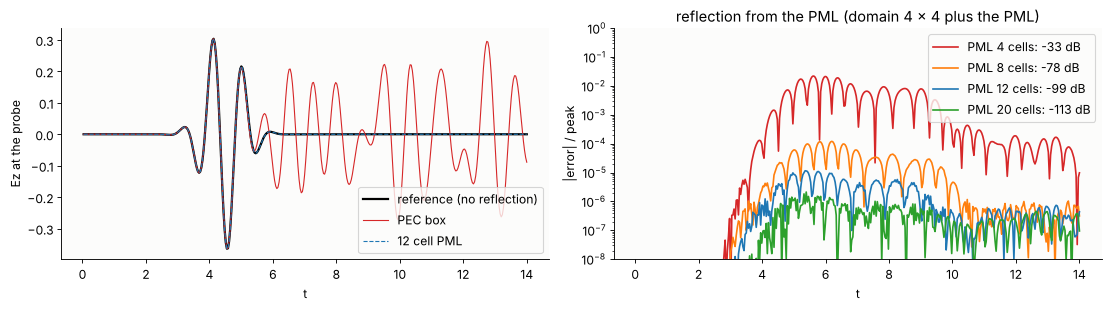

In [4]:
def probe_signal(L, boundaries, T=14.0):
    p = fdtd.Probe((1.5, 1.0))
    s = fdtd.Simulation(fdtd.Grid((L, L), WL/20), sources=[fdtd.PointSource((0, 0), pulse)],
                        monitors=[p], boundaries=boundaries)
    s.run(time=T)
    return p.times, p.values

t, ref = probe_signal(30.0, fdtd.PML(12))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for cells, color in ((4, "C3"), (8, "C1"), (12, "C0"), (20, "C2")):
    _, v = probe_signal(4 + 2*cells/20, fdtd.PML(cells))
    err = np.abs(v - ref)/np.abs(ref).max()
    ax2.semilogy(t, err + 1e-14, color=color,
                 label="PML %d cells: %.0f dB" % (cells, 20*np.log10(err.max())))
_, v_pec = probe_signal(5.2, "pec")
ax1.plot(t, ref, "k", lw=2, label="reference (no reflection)")
ax1.plot(t, v_pec, "C3", lw=1, label="PEC box")
_, v12 = probe_signal(5.2, fdtd.PML(12))
ax1.plot(t, v12, "C0--", lw=1, label="12 cell PML")
ax1.set_xlabel("t")
ax1.set_ylabel("Ez at the probe")
ax1.legend()
ax2.set_ylim(1e-8, 1)
ax2.set_xlabel("t")
ax2.set_ylabel("|error| / peak")
ax2.legend()
ax2.set_title("reflection from the PML (domain 4 × 4 plus the PML)")
plt.tight_layout()

Four cells reflect about −33 dB, eight about −80 dB and the default of 12
cells about −100 dB, far below the discretization error of any real
simulation. The
outer wall behind the PML is a PEC; the PML could also be thinner with a
larger `kappa_max` for grazing and evanescent waves, which are the hard
cases (planned for waveguide simulations).

## 3. 1D: a Bragg mirror over a whole band from one pulse

Five quarter-wave pairs (n = 2.3 and 1.45 at λ₀ = 1) on glass. A pulse with
35 % bandwidth hits the stack; `Flux` monitors in front of and behind it
accumulate running DFTs of E and H at 161 wavelengths. A reference run
without the stack gives the incident power; then

$$R(\lambda) = 1 - \frac{P_\text{front}}{P_\text{inc}},\qquad
T(\lambda) = \frac{P_\text{back}}{P_\text{inc}}.$$

The x-t diagram of the field shows the pulse entering, slowing down, and the
reflected pulse with its long ringing tail (the stop band edges are sharp,
so their delay is long).

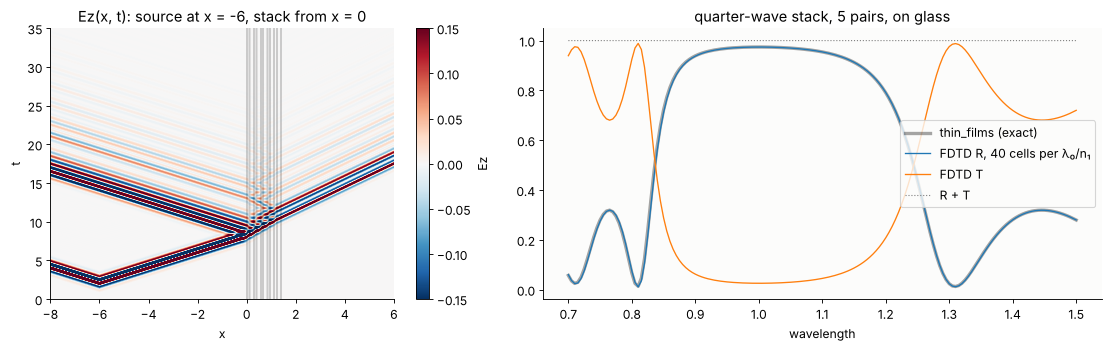

In [5]:
n1, n2, n_sub, N = 2.3, 1.45, 1.52, 5
d1, d2 = WL/4/n1, WL/4/n2
layers, x = [], 0.0
for _ in range(N):
    layers.append((fdtd.Slab(x, x + d1), fdtd.Medium.from_index(n1)))
    layers.append((fdtd.Slab(x + d1, x + d1 + d2), fdtd.Medium.from_index(n2)))
    x += d1 + d2
stack_end = x
layers.append((fdtd.Slab(stack_end, 100), fdtd.Medium.from_index(n_sub)))
wls = np.linspace(0.7, 1.5, 161)
pulse1d = fdtd.GaussianPulse(WL, bandwidth=0.35)

def bragg(ppw, structure, snapshots=None):
    front, back = fdtd.Flux(-3, wls), fdtd.Flux(stack_end + 2, wls)
    mons = [front, back] + ([snapshots] if snapshots else [])
    s = fdtd.Simulation(fdtd.Grid(20.0, WL/n1/ppw), structure,
                        [fdtd.PointSource(-6, pulse1d)], mons, boundaries=fdtd.PML(40))
    s.run(time=60)
    return s, front.flux(), back.flux()

snap1d = fdtd.Snapshots(every=4, region=((-8, 6),))
sim1d, f_front, f_back = bragg(40, layers, snap1d)
_, inc, _ = bragg(40, [])
R, T = 1 - f_front/inc, f_back/inc

def exact_R(wl):
    return abs(r_t_coeffs(0, [n1, n2]*N, [0]*2*N, [d1, d2]*N, 1, 0, n_sub, 0, "s", wl)[0])**2
R_exact = np.array([exact_R(w) for w in wls])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
fplot.xt_diagram(snap1d.stack(), ax=ax1, sim=sim1d, vmax=0.15)
ax1.set_ylim(0, 35)
ax1.set_title("Ez(x, t): source at x = -6, stack from x = 0")
ax2.plot(wls, R_exact, "k", lw=3, alpha=0.35, label="thin_films (exact)")
ax2.plot(wls, R, "C0", lw=1.2, label="FDTD R, 40 cells per λ₀/n₁")
ax2.plot(wls, T, "C1", lw=1.2, label="FDTD T")
ax2.plot(wls, R + T, "C7:", lw=1, label="R + T")
ax2.set_xlabel("wavelength")
ax2.legend(loc="center right")
ax2.set_title("quarter-wave stack, 5 pairs, on glass")
plt.tight_layout()

**Convergence.** The error falls with the square of the cell size, as it
should for the Yee scheme, once the permittivity is averaged across cells
that contain an interface (`subpixel`, default 64 samples per cell in 1D).
Without averaging (staircase, `subpixel=1`) the interfaces snap to the grid
and the error falls only linearly.

In [6]:
rows = []
for ppw in (10, 20, 40, 80):
    errs = []
    for sub in (1, None):
        front, back = fdtd.Flux(-3, wls), fdtd.Flux(stack_end + 2, wls)
        grid1d = fdtd.Grid(20.0, WL/n1/ppw)
        ref_ = fdtd.Flux(-3, wls)
        fdtd.Simulation(grid1d, [], [fdtd.PointSource(-6, pulse1d)], [ref_],
                        boundaries=fdtd.PML(40)).run(time=60)
        fdtd.Simulation(grid1d, layers, [fdtd.PointSource(-6, pulse1d)], [front, back],
                        boundaries=fdtd.PML(40), subpixel=sub).run(time=60)
        errs.append(np.abs(1 - front.flux()/ref_.flux() - R_exact).max())
    rows.append((ppw, *errs))
print("cells per λ₀/n₁   max |ΔR| staircase   max |ΔR| averaged")
for ppw, e1, e2 in rows:
    print("%10d          %10.4f           %10.4f" % (ppw, e1, e2))

cells per λ₀/n₁   max |ΔR| staircase   max |ΔR| averaged
        10              0.3279               0.2812
        20              0.1336               0.1040
        40              0.0907               0.0225
        80              0.0404               0.0044


## 4. Scattering by a cylinder: total field / scattered field

A plane wave is injected on the boundary of a box (`TFSF`): inside the box
the simulation carries the total field, outside only the scattered field.
The incident wave comes from an auxiliary 1D grid with the same cell size
and time step; along the grid axis its numerical dispersion is identical to
that of the 2D grid, so without a scatterer the field outside the box is
zero to round-off (about 1e-16).

The scatterer is a glass cylinder (n = 1.5) of radius 0.8λ, the Ez
polarization (E along the cylinder axis), which is the TE case of
`analytical.cylinder_field`. A `DFTField` monitor accumulates the complex
amplitude at λ = 1 during a pulse; dividing by the amplitude of the
incident wave at the centre (from a run without the cylinder) gives the
total field for a unit plane wave $e^{ikx}$, in the pyoptics convention.

two runs: 4.0 s


max error 0.062, rms 0.017 (incident amplitude 1)


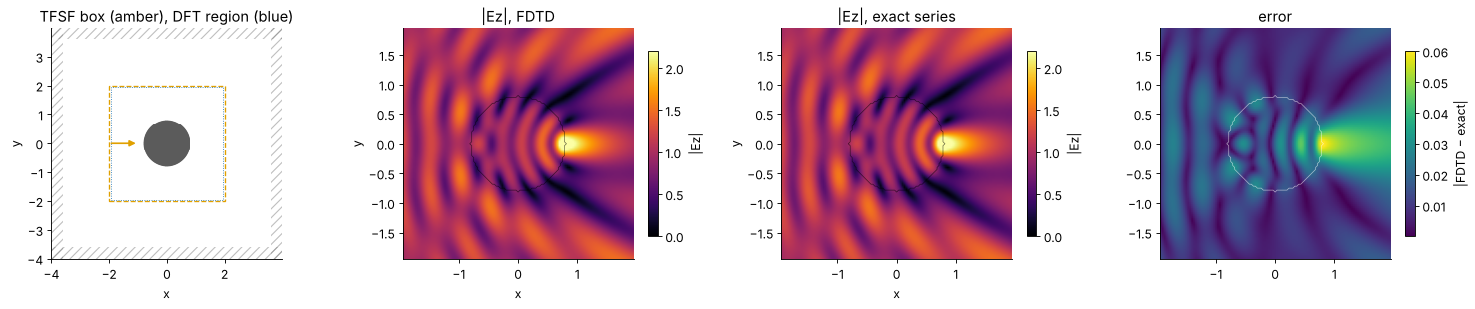

In [7]:
R_CYL, N_CYL = 0.8, 1.5

def cylinder_run(ppw, structure, mode="Ez", T=45.0, extra=()):
    comp = "Ez" if mode == "Ez" else "Hz"
    dft = fdtd.DFTField(WL, components=[comp], region=((-1.95, 1.95), (-1.95, 1.95)))
    s = fdtd.Simulation(fdtd.Grid((8.0, 8.0), WL/N_CYL/ppw), structure,
                        [fdtd.TFSF((-2.0, 2.0, -2.0, 2.0), fdtd.GaussianPulse(WL, 0.15))],
                        [dft, *extra], mode=mode, boundaries=fdtd.PML(12))
    s.run(time=T)
    return s, dft

cyl = [(fdtd.Circle((0, 0), R_CYL), fdtd.Medium.from_index(N_CYL))]
t0 = time.perf_counter()
_, dft_inc = cylinder_run(20, [])
sim_c, dft_c = cylinder_run(20, cyl)
print("two runs: %.1f s" % (time.perf_counter() - t0))

x, y = dft_c.coords("Ez")
i0, j0 = np.argmin(np.abs(x)), np.argmin(np.abs(y))
F = dft_c.field("Ez")[0]/dft_inc.field("Ez")[0][i0, j0]
X, Y = np.meshgrid(x, y, indexing="ij")
exact = cylinder_field(Y, X, R_CYL, N_CYL, WL)   # its z axis (propagation) is our x axis

fig, axs = plt.subplots(1, 4, figsize=(19, 4))
fplot.plot_structure(sim_c, ax=axs[0])
axs[0].set_title("TFSF box (amber), DFT region (blue)")
data = fdtd.DFTFieldData([WL], {"Ez": F[None]}, {"Ez": (x, y)})
fplot.plot_field(data, ax=axs[1], sim=sim_c, part="abs", vmax=2.2, title="|Ez|, FDTD")
fplot.plot_field(fdtd.DFTFieldData([WL], {"Ez": exact[None]}, {"Ez": (x, y)}), ax=axs[2],
                 sim=sim_c, part="abs", vmax=2.2, title="|Ez|, exact series")
err = np.abs(F - exact)
im = axs[3].imshow(err.T, origin="lower", cmap="viridis", extent=fplot._extent((x, y)), vmax=0.06)
fplot._structure_outline(axs[3], sim_c, color="w")
axs[3].set_xlim(fplot._extent((x, y))[:2]); axs[3].set_ylim(fplot._extent((x, y))[2:])
plt.colorbar(im, ax=axs[3], shrink=0.8, label="|FDTD − exact|")
axs[3].set_title("error")
plt.tight_layout()
print("max error %.3f, rms %.3f (incident amplitude 1)" % (err.max(), np.sqrt(np.mean(err**2))))

The cylinder focuses the wave just behind its rear surface (|E| ≈ 2.5, the
2D analogue of a photonic nanojet behind a ball lens, notebook
[05](05_WPM.ipynb)); in front of it the reflected wave interferes with the
incident one. The error is a few percent at 20 cells per wavelength in the
glass, largest in the focus, whose position depends on the discretized
circle and on the numerical dispersion. It falls with the square of the
cell size:

In [8]:
for ppw in (10, 20, 30):
    _, d0 = cylinder_run(ppw, [])
    _, d1 = cylinder_run(ppw, cyl)
    xx, yy = d1.coords("Ez")
    XX, YY = np.meshgrid(xx, yy, indexing="ij")
    FF = d1.field("Ez")[0]/d0.field("Ez")[0][np.argmin(np.abs(xx)), np.argmin(np.abs(yy))]
    e = np.abs(FF - cylinder_field(YY, XX, R_CYL, N_CYL, WL))
    print("%2d cells per λ/n: max error %.4f, rms %.4f" % (ppw, e.max(), np.sqrt(np.mean(e**2))))

10 cells per λ/n: max error 0.2568, rms 0.0693


20 cells per λ/n: max error 0.0619, rms 0.0169


30 cells per λ/n: max error 0.0278, rms 0.0076


**The steady state from one DFT.** For a monochromatic field, the complex
amplitude $F$ contains everything: $\mathrm{Re}\{F e^{-i\omega t}\}$ over
one period *is* the steady-state movie. `fplot.animate()` does this for a
DFT monitor; the 24 frames below need no stored time steps at all (one
complex array instead of hundreds of frames), and they are free of the
transients of the pulse.

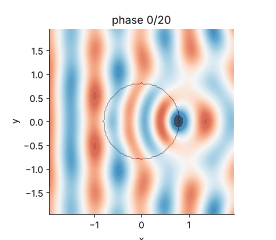

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 4.0))
anim = fplot.animate(data, sim=sim_c, ax=ax, frames=20, vmax=2.5)
plt.close(fig)
fplot.gif(anim, fps=10, dpi=60)

## 5. The two polarizations

The same cylinder in the Hz polarization (H along the axis, E in the
plane). Now E crosses the glass surface: its tangential part is continuous,
its normal part jumps by the ratio of the permittivities. For the series
solution, the boundary conditions change from continuous $u$ and
$\partial u/\partial r$ (Ez) to continuous $u$ and
$\varepsilon^{-1}\partial u/\partial r$ (Hz), which only changes the
coefficients:

$$a_m^{E} = \frac{m J_m'(m x)J_m(x) - J_m(m x)J_m'(x)}{J_m(m x)H_m'(x) - m J_m'(m x)H_m(x)},\qquad
a_m^{H} = \frac{J_m'(m x)J_m(x) - m J_m(m x)J_m'(x)}{m J_m(m x)H_m'(x) - J_m'(m x)H_m(x)},$$

($x = kR$, $m = n_\text{cyl}/n_\text{medium}$, outside field
$\sum_m i^m [J_m(kr) + a_m H_m(kr)]e^{im\varphi}$). The helper below
evaluates that series for Hz.

Hz mode, 20 cells per λ/n: max error 0.151, rms 0.029


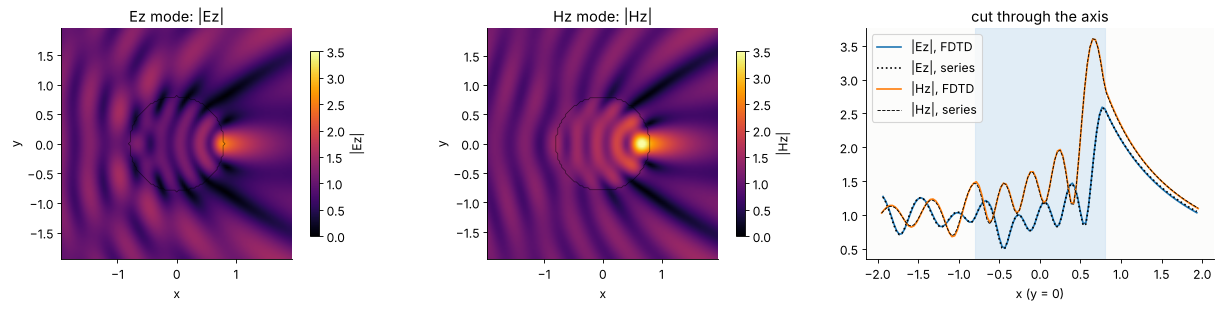

In [10]:
from scipy.special import jv, jvp, hankel1, h1vp

def cylinder_series(x, z, radius, n_cyl, wl, polarization="E", M=30):
    # exact total field for a unit plane wave exp(ikz), E or H along the axis
    k = 2*np.pi/wl
    kr, phi = k*np.hypot(x, z), np.arctan2(x, z)
    xr, m_rel = k*radius, n_cyl
    u = np.zeros(np.shape(kr), complex)
    for m in range(-M, M + 1):
        J, Jp, H, Hp = jv(m, xr), jvp(m, xr), hankel1(m, xr), h1vp(m, xr)
        Ji, Jip = jv(m, m_rel*xr), jvp(m, m_rel*xr)
        if polarization == "E":
            a = (m_rel*Jip*J - Ji*Jp)/(Ji*Hp - m_rel*Jip*H)
        else:
            a = (Jip*J - m_rel*Ji*Jp)/(m_rel*Ji*Hp - Jip*H)
        c = (J + a*H)/Ji          # continuity of u at r = R
        out = 1j**m*(jv(m, kr) + a*hankel1(m, kr))
        inside = 1j**m*c*jv(m, m_rel*kr)
        u += np.where(kr < xr, inside, out)*np.exp(1j*m*phi)
    return u

assert np.allclose(cylinder_series(Y, X, R_CYL, N_CYL, WL, "E"), exact, atol=1e-8)

_, dft_inc_h = cylinder_run(20, [], mode="Hz")
sim_h, dft_h = cylinder_run(20, cyl, mode="Hz")
xh, yh = dft_h.coords("Hz")
ih, jh = np.argmin(np.abs(xh)), np.argmin(np.abs(yh))
# Hz sits half a cell off the origin: refer the incident wave to x = 0
Fh = dft_h.field("Hz")[0]/dft_inc_h.field("Hz")[0][ih, jh]*np.exp(2j*np.pi*xh[ih]/WL)
XH, YH = np.meshgrid(xh, yh, indexing="ij")
exact_h = cylinder_series(YH, XH, R_CYL, N_CYL, WL, "H")
err_h = np.abs(Fh - exact_h)
print("Hz mode, 20 cells per λ/n: max error %.3f, rms %.3f" % (err_h.max(), np.sqrt(np.mean(err_h**2))))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
fplot.plot_field(data, ax=axs[0], sim=sim_c, part="abs", vmax=3.5, title="Ez mode: |Ez|")
fplot.plot_field(fdtd.DFTFieldData([WL], {"Hz": Fh[None]}, {"Hz": (xh, yh)}), ax=axs[1],
                 sim=sim_h, part="abs", vmax=3.5, title="Hz mode: |Hz|")
axs[2].axvspan(-R_CYL, R_CYL, color="#cfe3f3", alpha=0.6)
axs[2].plot(x, np.abs(F[:, j0]), "C0", label="|Ez|, FDTD")
axs[2].plot(x, np.abs(exact[:, j0]), "k:", label="|Ez|, series")
axs[2].plot(xh, np.abs(Fh[:, jh]), "C1", label="|Hz|, FDTD")
axs[2].plot(xh, np.abs(exact_h[:, jh]), "k--", lw=0.8, label="|Hz|, series")
axs[2].set_xlabel("x (y = 0)")
axs[2].legend()
axs[2].set_title("cut through the axis")
plt.tight_layout()

In the Hz mode the focus behind the cylinder is sharper and stronger
(|Hz| ≈ 3.6 against |Ez| ≈ 2.6). The FDTD follows the series in both
polarizations; in the Hz mode the error is about twice as large at the same
resolution (rms 0.03 against 0.017 here) and converges more slowly. The
arithmetic average of ε in the cells at the boundary is right for E
parallel to the interface, while E normal to it needs the harmonic mean.
The anisotropic sub-cell averaging (Farjadpour et al.) that uses the right
mean for each part is planned for the next milestone.

## 6. Storing results

A field snapshot of the 2D run in section 1 has 200 × 160 nodes. Stored as
float64, a recording of a few hundred frames already takes tens of MB; for
the large grids of real devices it quickly exceeds the memory. The levers,
in the order of their effect:

- **record only what is needed**: a `DFTField` at a few wavelengths instead
  of a time series (the steady-state movie above came from one complex
  array), a `Flux` line instead of a field, a `Probe` for spectra and
  ring-downs;
- **decimate in time** (`every`): a time step is 1/29 of a period here, a
  smooth movie needs 8 to 16 frames per period;
- **crop and subsample** (`region`, `stride`): the grid oversamples the
  field for accuracy, not for the picture;
- **float16** frames (`dtype`, the default for `Snapshots`): half of float32,
  plenty for a colour scale;
- a **ring buffer** (`keep_last`) when only the end of a run matters;
- **compression on disk**: `SnapshotStack.save()` writes compressed `.npz`,
  or HDF5 with gzip when the file name ends in `.h5` (optional `h5py`,
  `pip install pyoptics[hdf5]`); `Snapshots(path="run.h5")` streams the
  frames to the file during the run.

In [11]:
import os, tempfile
nx, ny = grid.shape
steps = int(16/sim.dt)
print("full time series, float64:  %6.1f MB" % (steps*nx*ny*8/1e6))
print("every 10th step, float64:   %6.1f MB" % (steps/10*nx*ny*8/1e6))
print("every 10th step, float16:   %6.1f MB  (the Snapshots of section 1: %.1f MB)"
      % (steps/10*nx*ny*2/1e6, stack.nbytes/1e6))
print("... and stride 2:           %6.1f MB" % (steps/10*nx*ny*2/4/1e6))
print("one complex DFT (complex128): %4.1f MB" % (nx*ny*16/1e6))
with tempfile.TemporaryDirectory() as d:
    for name in ("snaps.npz", "snaps.h5"):
        path = os.path.join(d, name)
        stack.save(path)
        print("%-10s on disk: %5.2f MB" % (name, os.path.getsize(path)/1e6))
    back = fdtd.SnapshotStack.load(os.path.join(d, "snaps.h5"))
    print("round trip exact:", np.array_equal(back.frames, stack.frames))

full time series, float64:   117.0 MB
every 10th step, float64:     11.7 MB
every 10th step, float16:      2.9 MB  (the Snapshots of section 1: 2.9 MB)
... and stride 2:              0.7 MB
one complex DFT (complex128):  0.5 MB
snaps.npz  on disk:  1.95 MB


snaps.h5   on disk:  1.72 MB
round trip exact: True


Lossless compression gains a further factor of about 1.5 here, more for
frames that are still mostly empty.

## Summary and outlook

- The Yee scheme with a CPML, soft sources and a TFSF plane wave reproduces
  the thin film reflectance of a Bragg mirror and the exact field of a
  dielectric cylinder (Ez) with second-order convergence; the discrete energy in
  a closed PEC box is conserved to round-off (`test/test_fdtd.py`).
- One pulse gives a whole spectrum; one DFT gives the steady state and its
  animation.
- Run times here are from the NumPy kernels (tens of millions of cell
  updates per second in 2D). The next milestone adds numba kernels
  (about 15× faster in a first benchmark),
  dispersive Drude/Lorentz media, waveguide mode sources and S-parameters,
  for directional couplers and ring resonators; see `proposals/fdtd.md`.